# Build the call tree of one amg run

You'll turn the call paths of one amg run into a call tree, find where its time goes with self time and a flame graph, and see which calls slow down when 16 processes share a node instead of 2.
It takes about 15 minutes of your time.

## Before you start

The first cell reads `runs` and opens the sample, as in [Find where amg spends its time](02-where-amg-spends-its-time.ipynb).

In [1]:
from dftracer.utils import Indexer, TraceViewer, col

with Indexer(files=["../data/genesis-sample.pfw.gz"]) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer("../data/genesis-sample.pfw.gz")
print(runs.shape)

(131, 10)


[2026-10-12 01:19:37.166] INFO  io_uring runtime probe failed, falling back (io_backend_factory.cpp:77)
[2026-10-12 01:19:37.166] INFO  I/O backend: using epoll+threadpool (48 threads) (io_backend_factory.cpp:95)
[2026-10-12 01:19:37.196] INFO  Resolver: 1 total, 1 cached, 0 need checkpoint, 0 need bloom, 0 need aggregation (resolver.cpp:443)


The plots show below each cell and go to `figures/` too.

In [2]:
import os

import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)

## 1. Load the call paths of one run

Take amg with the input `p1_n64x64x32` on one matrix node, one run for each number of processes.

In [3]:
amg = runs[
    (runs["app"] == "amg")
    & (runs["system"] == "matrix")
    & (runs["unique_input"] == "p1_n64x64x32")
    & (runs["nodes"] == 1)
]
print(amg[["run", "ppn", "papi_set"]].sort_values("ppn"))

                run  ppn                papi_set
0  454d63203964ed6e    2          papi_set2_flop
1  2eaa8a481d02f50f    4  papi_set1_branch_cycle
2  54a9d0e2fe7f511c    8          papi_set2_flop
3  849e23d3a37b6d84   16  papi_set1_branch_cycle


Load the call paths of the run with 16 processes.

In [4]:
RUN16 = amg[amg["ppn"] == 16]["run"].to_pandas().iloc[0]
func = tv.filter((col("gtype") == "func") & (col("run") == RUN16)).collect()
print(func.shape)

(419, 19)


Each record is one call path, such as `main;hypre_PCGSolve`.
`parent` is the path one level up, and `dur.sum` is the time of all calls of the path, summed over the processes.
So `parent` already gives the edges of the call tree.

## 2. Compute the self time of each call path

`dur.sum` of a path includes the time of its children.
Its self time is what is left after the children's time is taken away.
Sum the children by `parent` and join that sum back to each path.

In [5]:
def self_time(func):
    children = func.groupby("parent")[["dur.sum"]].sum()
    children = children.rename(columns={"parent": "path", "dur.sum": "children"})
    tree = func.merge(children, on="path", how="left")
    tree = tree.assign(children=tree["children"].fillna(0))
    return tree.assign(self_s=(tree["dur.sum"] - tree["children"]) / 1e6)


tree = self_time(func)
print(tree.nlargest(5, "self_s")[["name", "depth", "count", "self_s"]])

                              name  depth  count     self_s
0  hypre_CSRMatrixMatvecOutOfPlace      6   2816  11.361136
1  hypre_CSRMatrixMatvecOutOfPlace      5   1408   3.116187
2  hypre_CSRMatrixMatvecOutOfPlace      3    704   2.844579
3    hypre_BoomerAMGBuildMultipass      2     16   1.208623
4       hypre_BoomerAMGCoarsenPMIS      2     96   0.930828


A path with no children keeps all its time.
The self times add up to the time of the roots, the paths at depth 0, so nothing is counted twice.

In [6]:
roots = tree[tree["depth"] == 0]
print(roots[["name", "dur.sum"]])
print(round(tree["self_s"].sum(), 3), round(roots["dur.sum"].sum() / 1e6, 3))

      name       dur.sum
0  vfscanf  1.933790e+05
1    fgets  2.389000e+03
2    fopen  1.639490e+05
3     main  2.909649e+07
29.456 29.456


Besides `main`, the run has three small roots, file reads that run outside `main`.

## 3. Sum the self time of each function

`hypre_CSRMatrixMatvecOutOfPlace` shows up at three depths above, called from three places.
Group the self time by `name` to see each function in one row.

In [7]:
by_name = tree.groupby("name")[["self_s"]].sum().nlargest(10, "self_s")
print(by_name)

                              name     self_s
0  hypre_CSRMatrixMatvecOutOfPlace  17.321902
1    hypre_BoomerAMGBuildMultipass   1.208623
2                      MPI_Waitall   1.053143
3       hypre_BoomerAMGCoarsenPMIS   0.930828
4                    MPI_Allreduce   0.904195
5                        MPI_Bcast   0.878267
6        hypre_BoomerAMGCreate2ndS   0.629066
7                  hypre_ParMatmul   0.606410
8         hypre_ParMatmul_RowSizes   0.540601
9                     hypre_CAlloc   0.503275


The sparse matrix-vector product takes most of the time of this run.

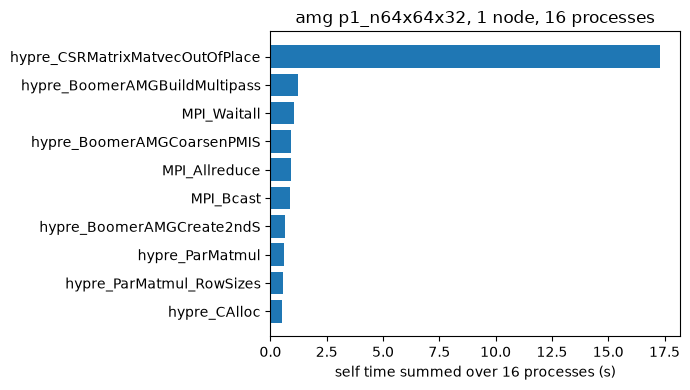

In [8]:
top = by_name.to_pandas()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top["name"][::-1], top["self_s"][::-1])
ax.set_xlabel("self time summed over 16 processes (s)")
ax.set_title("amg p1_n64x64x32, 1 node, 16 processes")
fig.tight_layout()
fig.savefig("../figures/self-time-16.png", dpi=120)
plt.show()

## 4. Draw the flame graph

A flame graph puts each call path in a box as wide as its time, with its children above it, widest first.
Place each child after its siblings inside its parent, starting from `main`.

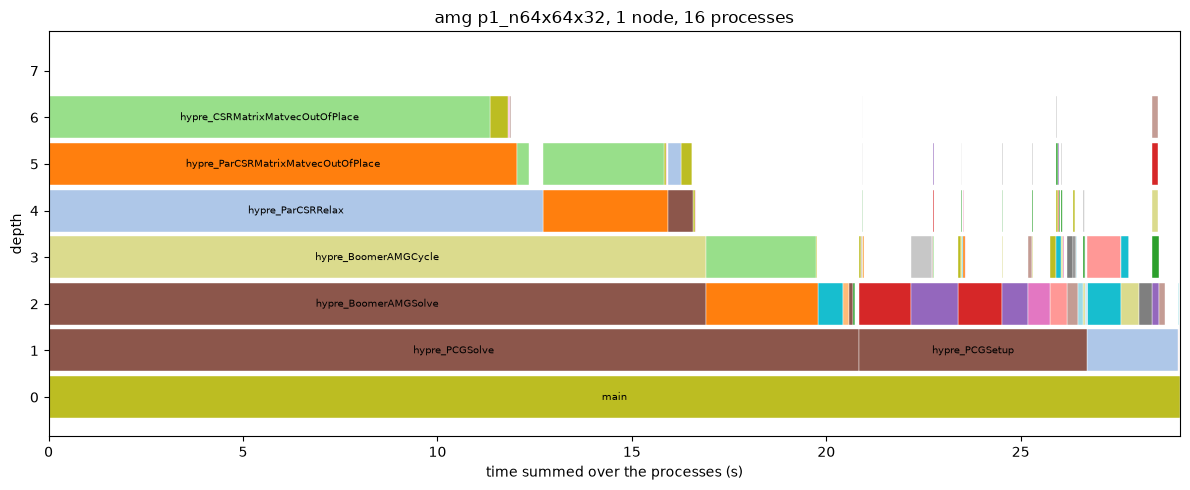

In [9]:
import zlib


def flame(tree, title, path):
    t = tree[["path", "parent", "name", "depth", "dur.sum"]].to_pandas()
    t["w"] = t["dur.sum"] / 1e6
    kids = {p: g.sort_values("w", ascending=False) for p, g in t.groupby("parent")}
    left = {}

    def place(p, x):
        left[p] = x
        if p not in kids:
            return
        for child, w in zip(kids[p]["path"], kids[p]["w"]):
            place(child, x)
            x += w

    place("main", 0.0)
    t = t[t["path"].isin(left)]
    width = t["w"].max()
    fig, ax = plt.subplots(figsize=(12, 5))
    colors = plt.get_cmap("tab20")
    for p, name, depth, w in zip(t["path"], t["name"], t["depth"], t["w"]):
        ax.barh(depth, w, left=left[p], height=0.9, edgecolor="white", linewidth=0.3,
                color=colors(zlib.crc32(name.encode()) % 20))
        if w > 0.009 * width * len(name):
            ax.text(left[p] + w / 2, depth, name, ha="center", va="center", fontsize=7)
    ax.set_xlim(0, width)
    ax.set_xlabel("time summed over the processes (s)")
    ax.set_ylabel("depth")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()


flame(tree, "amg p1_n64x64x32, 1 node, 16 processes", "../figures/flame-16.png")

`hypre_PCGSolve` takes about 70% of `main`, and most of it sits in the stack of `hypre_BoomerAMGCycle`, `hypre_ParCSRRelax` and the matrix-vector product at the top.
`hypre_PCGSetup` and `BuildIJLaplacian27pt`, the box at the right with no room for its name, fill most of the rest.

## 5. Compare 2 and 16 processes

Each process of these runs gets the same problem size, so the time per process would stay flat if the processes didn't get in each other's way.
Compute the self time per function and per process for the runs with 2 and 16 processes, and join them.

In [10]:
def per_process(ppn):
    run = amg[amg["ppn"] == ppn]["run"].to_pandas().iloc[0]
    f = tv.filter((col("gtype") == "func") & (col("run") == run)).collect()
    by_name = self_time(f).groupby("name")[["self_s"]].sum()
    return by_name.assign(**{f"p{ppn}": by_name["self_s"] / ppn})[["name", f"p{ppn}"]]


both = per_process(2).merge(per_process(16), on="name")
both = both.assign(grow=both["p16"] - both["p2"])
print(both.nlargest(6, "grow"))

                              name        p2       p16      grow
0  hypre_CSRMatrixMatvecOutOfPlace  0.451132  1.082619  0.631487
1                      MPI_Waitall  0.004603  0.065821  0.061218
2                        MPI_Bcast  0.000220  0.054892  0.054672
3                    MPI_Allreduce  0.004232  0.056512  0.052280
4                     hypre_CAlloc  0.002975  0.031455  0.028480
5    hypre_BoomerAMGBuildMultipass  0.052670  0.075539  0.022869


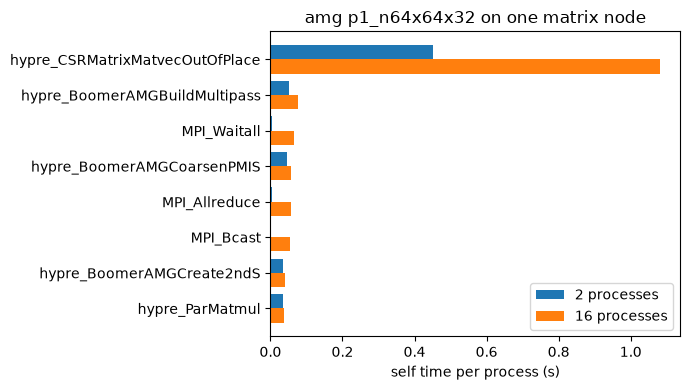

In [11]:
top = both.nlargest(8, "p16").to_pandas()[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([i + 0.2 for i in range(len(top))], top["p2"], height=0.4, label="2 processes")
ax.barh([i - 0.2 for i in range(len(top))], top["p16"], height=0.4, label="16 processes")
ax.set_yticks(range(len(top)), top["name"])
ax.set_xlabel("self time per process (s)")
ax.set_title("amg p1_n64x64x32 on one matrix node")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/self-2-vs-16.png", dpi=120)
plt.show()

The matrix-vector product takes 2.4 times as long per process with 16 processes, 0.45 s against 1.08 s, which is about two thirds of the growth of `main`.
It reads the whole matrix for little arithmetic, so memory bandwidth limits it, and 16 processes on one node share that bandwidth.
The MPI calls grow too, from almost nothing to about 0.05 s each per process.

## What you built

You built the call tree of a run from its `path` and `parent` columns, split its time into self time, drew it as a flame graph and found the calls that stop scaling on a full node.

- What the `func` fields mean: [Build per-function distributions from genesis traces](https://dftracer.readthedocs.io/projects/utils/en/latest/guides/tools/genesis-gen-dist.html)
- The pandas spellings the engine takes: [Python API Reference](https://dftracer.readthedocs.io/projects/utils/en/latest/api/index.html)